# 04 SQL: the same pipeline in SQL with DuckDB

**Step 9 (extension).** Notebooks 01 and 02 cleaned the transactions and built RFM in pandas. Here the same work is done in **SQL**, and the results are checked against the pandas versions. Then SQL answers two business questions pandas was not used for: what each segment is worth, and how well new customers are retained.

**Why DuckDB:** it is a SQL database that runs inside Python, with no server to install. It reads Parquet and CSV files directly and uses standard SQL (the same `GROUP BY`, `JOIN` and window functions you would write in PostgreSQL, SQL Server or a cloud warehouse).

The queries live in [`sql/`](../sql) as plain `.sql` files, so they can be read and reused without this notebook.

In [1]:
import matplotlib.pyplot as plt

# One consistent, colour-blind-safe look for every chart in this project
BLUE, ORANGE, AQUA, YELLOW, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#8a8984"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight",
    "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": GREY, "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.8,
    "axes.axisbelow": True, "axes.titleweight": "bold", "axes.titlesize": 12,
    "axes.titlelocation": "left", "axes.labelcolor": "#52514e",
    "xtick.color": "#52514e", "ytick.color": "#52514e", "font.size": 10,
    "legend.frameon": False, "lines.linewidth": 2,
    "axes.prop_cycle": plt.cycler(color=[BLUE, ORANGE, AQUA, YELLOW]),
})

from pathlib import Path
import duckdb
import numpy as np
import pandas as pd

SQL = Path("../sql")
RAW_XLSX = Path("../data/raw/online_retail_II.xlsx")
RAW_PARQUET = Path("../data/processed/transactions_raw.parquet")

def run(name):
    """Run one .sql file and return its result (if it has one) as a DataFrame."""
    result = con.sql(SQL.joinpath(f"{name}.sql").read_text())
    return result.df() if result is not None else None

## 1. Load the raw transactions into DuckDB

The raw Excel file (from Step 2) is read once and saved as Parquet, a fast columnar format that DuckDB queries directly. `Invoice`, `StockCode` and `Description` mix numbers and text in Excel, so they are stored as text.

In [2]:
if not RAW_PARQUET.exists():
    raw = pd.concat(pd.read_excel(RAW_XLSX, sheet_name=None).values(), ignore_index=True)
    raw = raw.astype({"Invoice": "string", "StockCode": "string", "Description": "string"})
    raw.to_parquet(RAW_PARQUET)

con = duckdb.connect()  # an in-memory database
con.sql(f"CREATE OR REPLACE VIEW raw_transactions AS SELECT * FROM '{RAW_PARQUET}'")
con.sql("SELECT count(*) AS lines, count(DISTINCT Invoice) AS invoices, count(\"Customer ID\") AS lines_with_customer FROM raw_transactions").df()

,lines,invoices,lines_with_customer
0,1067371,53628,824364


## 2. Clean the transactions in one query

[`sql/01_clean_transactions.sql`](../sql/01_clean_transactions.sql) applies the Step 3 rules: drop exact duplicates (`SELECT DISTINCT`), drop lines with no customer, drop cancellations (`C`) and adjustments (`A`), keep real products (`regexp_matches(StockCode, '^\d{5}')`), keep positive quantity and price, and compute revenue.

In [3]:
print(SQL.joinpath("01_clean_transactions.sql").read_text())

-- Step 9 | 01: Clean the raw transactions in SQL
-- Same rules as notebooks/01_clean.ipynb, written as one query.
-- Input:  raw_transactions (every invoice line, as loaded from the Excel file)
-- Output: transactions (real purchases by known customers, with revenue)

CREATE OR REPLACE TABLE transactions AS
WITH deduplicated AS (
    -- exact duplicate lines are double-recorded, keep one copy
    SELECT DISTINCT * FROM raw_transactions
)
SELECT
    Invoice                      AS invoice,
    InvoiceDate                  AS invoice_date,
    CAST("Customer ID" AS INTEGER) AS customer_id,
    Country                      AS country,
    StockCode                    AS stock_code,
    Description                  AS description,
    Quantity                     AS quantity,
    Price                        AS price,
    Quantity * Price             AS revenue
FROM deduplicated
WHERE "Customer ID" IS NOT NULL                -- purchase must belong to a customer
  AND NOT starts_with(Invo

In [4]:
run("01_clean_transactions")
sql_tx = con.sql("SELECT * FROM transactions").df()
py_tx = pd.read_parquet("../data/processed/transactions_clean.parquet")

pd.DataFrame({
    "pandas (Step 3)": [len(py_tx), py_tx.customer_id.nunique(), py_tx.invoice.nunique(), round(py_tx.revenue.sum(), 2)],
    "SQL": [len(sql_tx), sql_tx.customer_id.nunique(), sql_tx.invoice.nunique(), round(sql_tx.revenue.sum(), 2)],
}, index=["purchase lines", "customers", "invoices", "revenue (£)"])

,pandas (Step 3),SQL
purchase lines,776577.00,776577.00
customers,5852.00,5852.00
invoices,36594.00,36594.00
revenue (£),17068567.97,17068567.97


Identical. The SQL query and the pandas code make exactly the same cleaning decisions.

## 3. RFM with window functions

[`sql/02_rfm_scores.sql`](../sql/02_rfm_scores.sql) builds recency, frequency and monetary per customer with `GROUP BY`, then scores each from 1 to 5 with the window function `NTILE(5) OVER (ORDER BY ...)`, which splits the ordered customers into five equal-sized groups.

Two details worth knowing:

- **Recency** uses whole seconds divided by 86,400, so it counts *complete* days like pandas does. `date_diff('day', ...)` would count calendar boundaries crossed instead, which gives a different answer for a purchase late in the day.
- **Recency is reversed** (`6 - NTILE(5)`): fewer days since the last order is better, so the most recent fifth gets 5.

In [5]:
print(SQL.joinpath("02_rfm_scores.sql").read_text())

-- Step 9 | 02: RFM per customer, scored 1 to 5 with window functions
-- Same idea as notebooks/02_rfm.ipynb, but in SQL.

CREATE OR REPLACE TABLE rfm AS
WITH snapshot AS (
    -- the day after the last sale, so the most recent buyer has recency 0
    SELECT date_trunc('day', max(invoice_date)) + INTERVAL 1 DAY AS snapshot_date
    FROM transactions
),
per_customer AS (
    SELECT
        customer_id,
        -- whole days since the last order (same as pandas Timedelta.days)
        date_diff('second', max(invoice_date), (SELECT snapshot_date FROM snapshot)) // 86400 AS recency,
        count(DISTINCT invoice) AS frequency,
        round(sum(revenue), 2)  AS monetary
    FROM transactions
    GROUP BY customer_id
),
scored AS (
    SELECT
        *,
        6 - NTILE(5) OVER (ORDER BY recency, customer_id) AS R,  -- most recent fifth gets 5
        NTILE(5) OVER (ORDER BY frequency, customer_id)   AS F,  -- most orders gets 5
        NTILE(5) OVER (ORDER BY monetary, customer_id)    AS

In [6]:
run("02_rfm_scores")
sql_rfm = con.sql("SELECT * FROM rfm").df().set_index("customer_id")
py_rfm = pd.read_csv("../data/processed/rfm.csv", index_col="customer_id")

check = pd.Series({
    "recency": (sql_rfm.recency == py_rfm.recency).mean(),
    "frequency": (sql_rfm.frequency == py_rfm.frequency).mean(),
    "monetary": (np.isclose(sql_rfm.monetary, py_rfm.monetary, atol=0.01)).mean(),
    "R score": (sql_rfm.R == py_rfm.R).mean(),
    "F score": (sql_rfm.F == py_rfm.F).mean(),
    "M score": (sql_rfm.M == py_rfm.M).mean(),
    "tier": (sql_rfm.tier == py_rfm.tier).mean(),
}, name="share of customers that match")
check.map("{:.2%}".format).to_frame()

,share of customers that match
recency,100.00%
frequency,100.00%
monetary,100.00%
R score,99.06%
F score,99.95%
M score,99.95%
tier,99.79%


In [7]:
pd.crosstab(py_rfm.tier, sql_rfm.tier, rownames=["pandas tier"], colnames=["SQL tier"])

SQL tier,Bronze,Gold,Silver
pandas tier,,,
Bronze,1763,0,0
Gold,0,1702,9
Silver,3,0,2375


**The raw recency, frequency and monetary values match for every customer.** The scores differ for a few customers because of **ties**:

- `pd.qcut` puts all customers with the same value into the same score, so the five groups are not exactly equal in size.
- `NTILE` makes the five groups exactly equal in size, so customers tied right on a boundary can be split between two scores (here the tie is broken by customer ID).

Recency has the most ties (hundreds of customers last bought on the same day), so its scores differ the most, and still only for about 1 customer in 100. The tiers differ for about 12 of 5,852 customers. Neither method is wrong; they handle ties differently, and it is worth knowing which one a report used.

## 4. What is each segment worth?

[`sql/03_segment_summary.sql`](../sql/03_segment_summary.sql) joins the Step 7 segment labels back to every purchase line. It uses `sum(sum(revenue)) OVER ()` (a window over the grouped result) for each segment's share of revenue, and `FILTER (WHERE ...)` for revenue in the last 90 days.

In [8]:
con.sql("CREATE OR REPLACE TABLE segments AS SELECT * FROM read_csv('../reports/segments.csv')")
summary = run("03_segment_summary").set_index("segment")
summary

,customers,orders,orders_per_customer,avg_order_value,revenue,pct_of_revenue,revenue_last_90_days
segment,,,,,,,
Loyal big spenders,1110,22049,19.9,554.0,12217497.0,71.6,2515098.0
Drifting regulars,1468,7993,5.4,394.0,3150628.0,18.5,253328.0
New and promising,1220,3631,3.0,276.0,1002636.0,5.9,577416.0
Lapsed one-time buyers,2054,2921,1.4,239.0,697806.0,4.1,31902.0


In [9]:
recent_share = (summary.revenue_last_90_days / summary.revenue_last_90_days.sum() * 100).round(1)
print("Share of the LAST 90 DAYS of revenue:")
print(recent_share.to_string())

Share of the LAST 90 DAYS of revenue:
segment
Loyal big spenders        74.5
Drifting regulars          7.5
New and promising         17.1
Lapsed one-time buyers     0.9


Three things stand out:

1. **Loyal big spenders** place about 20 orders each, with the largest baskets, and still bring in about three quarters of the revenue in the last 90 days. They are the business.
2. **New and promising** customers are only about 6% of all revenue, but about 17% of the *recent* revenue. They are where next year's loyal customers come from, which is why Step 7 gives them a welcome series.
3. **Lapsed one-time buyers** have the smallest baskets and under 1% of recent revenue. Spending individual effort on them would not pay back.

## 5. Cohort retention: do new customers come back?

[`sql/04_cohort_retention.sql`](../sql/04_cohort_retention.sql) groups customers by the month of their **first** order (their cohort) and counts how many ordered again in each later month. This is a standard SQL pattern: CTEs (`WITH ...`) for each building block, `date_trunc` to months, `date_diff` for months since the first order, and a window `max(...) OVER (PARTITION BY cohort_month)` for the cohort size.

In [10]:
cohorts = run("04_cohort_retention")
retention = cohorts.pivot(index="cohort_month", columns="months_since_first", values="pct_retained")
retention.index = pd.to_datetime(retention.index).strftime("%b %Y")
retention.iloc[:12, :13]

months_since_first,0,1,2,3,4,5,6,7,8,9,10,11,12
cohort_month,,,,,,,,,,,,,
Dec 2009,100.0,35.0,33.3,42.5,37.9,36.0,37.6,34.4,33.8,36.2,42.2,49.6,37.6
Jan 2010,100.0,21.5,32.1,31.5,27.2,31.0,26.9,23.4,28.5,32.6,31.0,17.9,22.8
Feb 2010,100.0,23.5,22.7,29.3,24.5,19.7,19.2,28.8,25.6,27.7,11.5,12.5,15.2
Mar 2010,100.0,19.0,23.1,24.3,23.1,20.4,24.7,30.6,27.7,10.9,11.6,14.5,20.0
Apr 2010,100.0,19.0,19.0,16.0,18.4,22.1,27.6,26.5,10.5,10.9,7.5,13.9,14.3
May 2010,100.0,15.7,16.9,17.6,17.6,25.5,21.2,12.5,5.9,8.2,11.4,13.3,15.3
Jun 2010,100.0,17.6,18.7,20.6,23.2,28.5,12.7,9.0,8.2,11.2,10.5,13.9,15.0
Jul 2010,100.0,15.7,18.4,29.7,29.2,14.1,11.4,14.6,14.6,11.4,13.5,14.6,13.0
Aug 2010,100.0,19.6,28.8,32.5,16.6,11.7,9.8,12.9,13.5,12.9,12.9,11.7,14.7


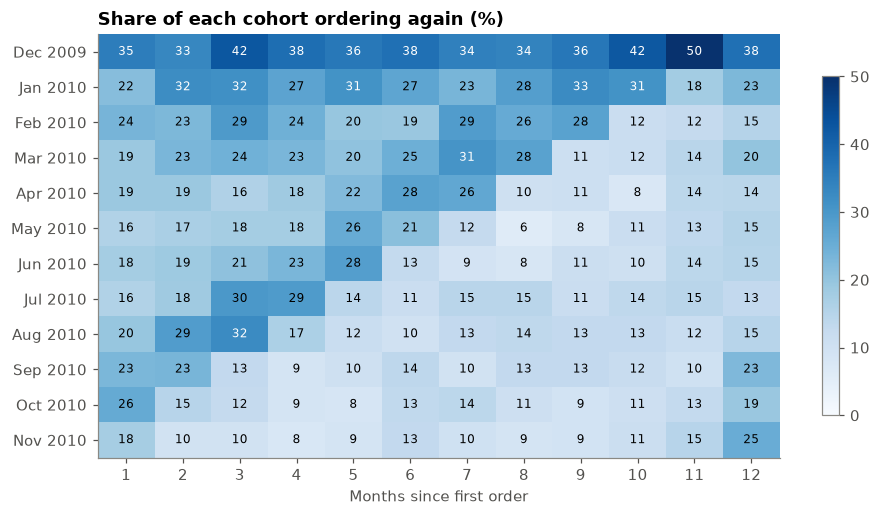

In [11]:
grid = retention.iloc[:12, 1:13]
fig, ax = plt.subplots(figsize=(10, 5))
im = ax.imshow(grid.values, cmap="Blues", vmin=0, vmax=50, aspect="auto")
ax.set_xticks(range(grid.shape[1]), grid.columns)
ax.set_yticks(range(grid.shape[0]), grid.index)
for i in range(grid.shape[0]):
    for j in range(grid.shape[1]):
        v = grid.values[i, j]
        if not np.isnan(v):
            ax.text(j, i, f"{v:.0f}", ha="center", va="center", fontsize=8, color="white" if v > 30 else "black")
ax.set_xlabel("Months since first order")
ax.set_title("Share of each cohort ordering again (%)")
ax.grid(False)
fig.colorbar(im, ax=ax, shrink=0.8)
fig.savefig("../figures/cohort_retention.png")
plt.show()

In [12]:
first_year = retention.iloc[:12]
print(f"December 2009 cohort ordering again one month later: {retention.iloc[0, 1]:.0f}%")
print(f"Later 2010 cohorts, median one month later: {first_year.iloc[1:, 1].median():.0f}%")

December 2009 cohort ordering again one month later: 35%
Later 2010 cohorts, median one month later: 19%


**Reading the grid:** the **December 2009** row is unusually strong. It is not a single cohort of new customers: the data starts in December 2009, so every existing customer appears to be "new" that month, and it is full of established regulars. For genuinely new customers (2010 onwards), only about **1 in 5 orders again the next month**, and after six months it settles at roughly 10 to 15%. The one clear lift is seasonal: each cohort comes back more when it reaches the October and November peak (for example the July and August 2010 cohorts, two to four months after their first order).

That supports the **New and promising** campaign in Step 7: the weeks right after the first order are when most new customers are lost, so the welcome series should start immediately, not wait for the next seasonal email.

## 6. What the SQL version adds

1. **The cleaning and RFM logic is now portable.** The `.sql` files would run, with small changes, on the retailer's own database, so the segmentation could be refreshed every month without Python.
2. **It is checked.** The SQL output matches the pandas output exactly for the raw values, and the small score differences are explained (ties).
3. **Two new answers:** each segment's share of *recent* revenue, and how quickly new customers drop off.